# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# importar librerías

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código


In [3]:
plans.head(5)# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5)# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("_latam", users.shape)
print("usage", usage.shape)

plans (2, 8)
_latam (4000, 8)
usage (40000, 6)


In [7]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos
print(users.isnull().mean()*100)# Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())# Cantidad de valores nulos
print(usage.isnull().mean()*100)# Proporción de valores nulos

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

Se evidencia se presenta valores nulos es `churn_date`, con 462 registros vacíos, lo que corresponde al **92,4% del total de clientes**,`date` con un 0.12% de valores nulos, `duration` con un 55.19% de valores nulos y  `length` con un 44.74%, se recomienda revisar columna `churn_date` si corresponde realmente a clientes que han cancelado el servicio, `duration` y `length` se debe revisar si es necesario imputar o mantener. 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
users.describe()# explorar columnas numéricas de users

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000




- La columna `user_id` corresponde a una totalidad de 500 usuarios, al ser una variable identificadora, la media y la desviación estándar no son métricas relevantes para detectar anomalías. Se debe comprobar principalmente la existencia de valores duplicados.
  
- La columna `age` la edad presenta una media de 46.58 años y una desviación estándar de 16.66 años, con valores entre 18 y 75 años. El rango observado no evidencia, por sí solo, valores anómalos. No obstante, se recomienda verificar posibles sentinels antes de continuar con el análisis.



In [13]:
usage.describe()
# explorar columnas numéricas de usage

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000



Las columnas `id` y `user_id` presentan 40.000 registros cada una. Se recomienda verificar la existencia de registros duplicados, especialmente en id, ya que debería identificar de manera única cada registro. Para `user_id`, es normal que un mismo usuario pueda aparecer en múltiples registros.

La columna `duration` presenta una media de 5,20 minutos y una desviación estándar de 6,84, mientras que `length` presenta una media de 52,13 y una desviación estándar de 56,61. En ambas variables se observa una dispersión considerable respecto a sus medias.
Además, los valores máximos son considerablemente superiores a los valores centrales: `duration` alcanza 120 minutos, mientras que `length` llega hasta 1.490. Esto puede indicar la presencia de valores atípicos (outliers) o, dependiendo del significado de las variables, posibles valores sentinela. Se recomienda realizar una revisión adicional (IQR).


In [14]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(f"\nValores únicos de {columna}:")
    print(users[columna].unique())



Valores únicos de city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Valores únicos de plan:
['Basico' 'Premium']


- La columna `city` se comprueba que existen valos que no corresponden como '?' y 'nan', se deben remplazar estos registo por Nan.
- La columna `plan` se comprueba que solo existen dos tipos de tarifas 'Basico' y 'Premium'.

In [15]:

# explorar columna categórica de usage
usage['type'].describe()
# completa el código


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` contiene 40.000 registros y presenta 2 categorías únicas: text y call. La categoría con mayor frecuencia es text, con 22.092 registros, lo que representa el 55,23 % del total. Por lo tanto, call representa los 17.908 registros restantes (44,77 %).

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 


**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- Se encuentran posibles outliers o sentinels en la tabla usage correspondientes a las columnas 'duration' y 'length'.
- ¿Qué acción tomarías?
Antes de eliminarlos, se debe verificar si representan valores reales o datos inválidos. Se recomienda utilizar el método IQR y revisar los registros afectados antes de tomar una decisión.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] =  pd.to_datetime(users['reg_date'])
 # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])# completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.unique())

[2022 2026 2023 2024]


En `reg_date` muestra que los registros de los clientes corresponden a los años 2022,2023,2024. se encuentra registros que corresponde al año 2026, se debe revisar si corresponde a un error.

In [19]:

# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.unique())


[2024.   nan]


En `date` se identificó que los registros corresponden al año 2024, aunque también existen valores nulos (NaN). Por esta razón, es necesario revisar la cantidad y proporción de fechas faltantes antes de realizar el análisis, ya que estos registros podrían afectar los resultados.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:

# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
(users['city'] == "?").sum()
users['city'].head(5)

0    Medellín
1        <NA>
2        CDMX
3      Bogotá
4         GDL
Name: city, dtype: object

In [22]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > pd.Timestamp.now(), 'reg_date'] = pd.NaT


print((users['reg_date'] > pd.Timestamp.now()).sum())
# Verificar cambios


0


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration

usage["duration"].isna().groupby(usage["type"]).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage["length"].isna().groupby(usage["type"]).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Se comprueba que los valores faltantes en las columnas `duration` y `length` están relacionados con la variable `type`. La ausencia de estos datos no parece ser aleatoria, sino que depende de la categoría del registro. En particular, los valores faltantes corresponden a la categoría MAR, por lo que se debe tener en cuenta esta relación antes de realizar cualquier tratamiento de los datos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:


# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage[["user_id","duration","length","is_text","is_call"]].groupby(["user_id"]).sum().reset_index()


# observar resultado
usage_agg.head(3)



,user_id,duration,length,is_text,is_call
0,10000,23.70,258.0,7,3
1,10001,33.18,226.0,5,10
2,10002,10.74,225.0,5,2


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"duration": "cant_minutos_llamada","is_text": "cant_mensajes","is_call": "cant_llamadas"})
# observar resultado
usage_agg.head(3)

,user_id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas
0,10000,23.70,258.0,7,3
1,10001,33.18,226.0,5,10
2,10002,10.74,225.0,5,2


In [27]:
# Combinar la tabla agregada con el dataset de usuarios

user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamada,length,cant_mensajes,cant_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,258.0,7.0,3.0
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,226.0,5.0,10.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,225.0,5.0,2.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,530.0,11.0,3.0
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,229.0,4.0,3.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:

# Resumen estadístico de las columnas numéricas
user_profile.describe()


,user_id,age,cant_minutos_llamada,length,cant_mensajes,cant_llamadas
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.122250,23.317054,288.128032,5.524381,4.478120
std,1154.844867,17.690408,18.168095,180.906841,2.358416,2.144238
min,10000.000000,18.000000,0.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,11.120000,184.000000,4.000000,3.000000
50%,11999.500000,47.000000,19.780000,268.000000,5.000000,4.000000
75%,12999.250000,63.000000,31.415000,361.000000,7.000000,6.000000
max,13999.000000,79.000000,155.690000,2028.000000,17.000000,15.000000


In [29]:
# Distribución porcentual del tipo de plan
(user_profile.value_counts("plan")/4000)*100

plan
Basico     64.875
Premium    35.125
dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

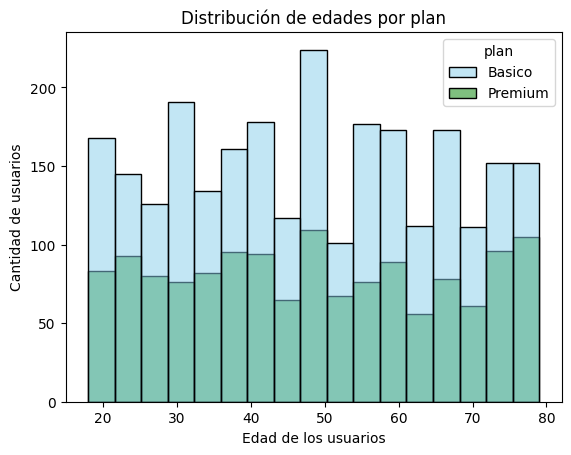

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,x="age", hue="plan",palette=["skyblue", "green"])
plt.title("Distribución de edades por plan")
plt.xlabel("Edad de los usuarios")
plt.ylabel("Cantidad de usuarios")   
plt.show()



💡Insights: 
Se evidencia que el plan Básico concentra el 64,87% de los clientes, por lo que presenta una mayor participación en comparación con el plan Premium con un 35.12%.

En cuanto a la distribución por edades, se observa una mayor concentración de usuarios alrededor de los 50 años en ambos planes. Esto sugiere que este grupo de edad tiene una presencia importante tanto entre los clientes del plan Básico como entre los del plan Premium.

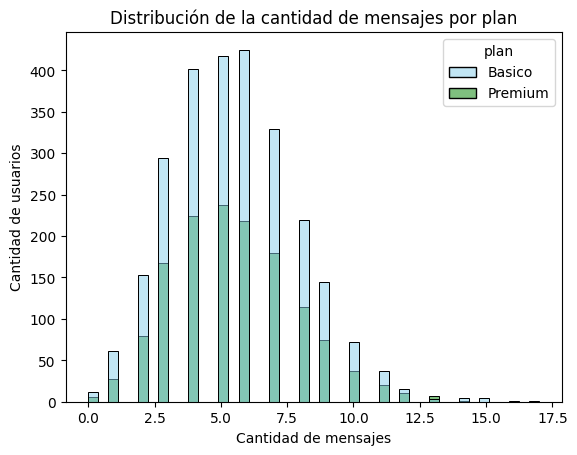

In [31]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile,x="cant_mensajes", hue="plan",palette=["skyblue", "green"])
plt.title("Distribución de la cantidad de mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")   
plt.show()


💡Insights: 
Se evidencia que la cantidad de mensajes se concentra principalmente entre los valores de 5 y 7 en ambos planes, con una mayor frecuencia en el plan Básico. A medida que aumenta la cantidad de mensajes, disminuye la frecuencia de usuarios.

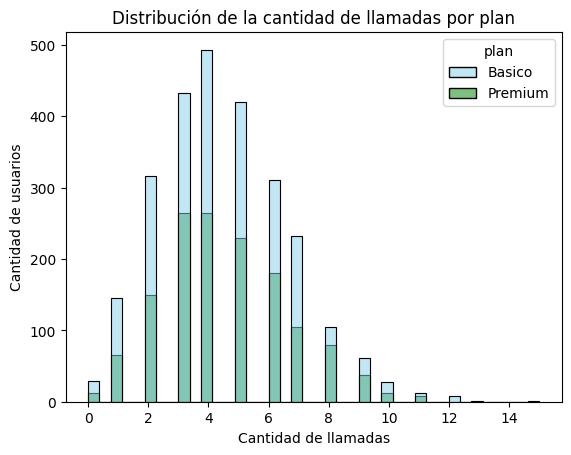

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,x="cant_llamadas", hue="plan",palette=["skyblue", "green"])
plt.title("Distribución de la cantidad de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")   
plt.show()

💡Insights: 
La distribución de las llamadas se concentra principalmente entre 3 y 5 en ambos planes, se evidencia sesgo hacia la derecha.

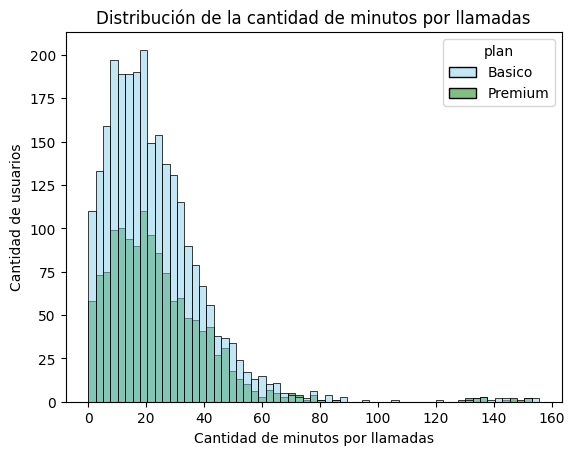

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,x="cant_minutos_llamada", hue="plan",palette=["skyblue", "green"])
plt.title("Distribución de la cantidad de minutos por llamadas")
plt.xlabel("Cantidad de minutos por llamadas")
plt.ylabel("Cantidad de usuarios")   
plt.show()



💡Insights: 
Se evidencia una distribución sesgada hacia la derecha en ambos planes, con una mayor concentración de llamadas de entre 6 y 20 minutos. Se recomienda revisar los valores extremos para determinar si corresponden a posibles outliers o valores inválidos (sentinels).

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

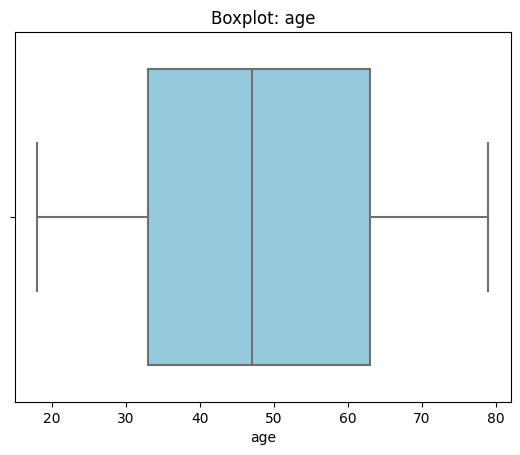

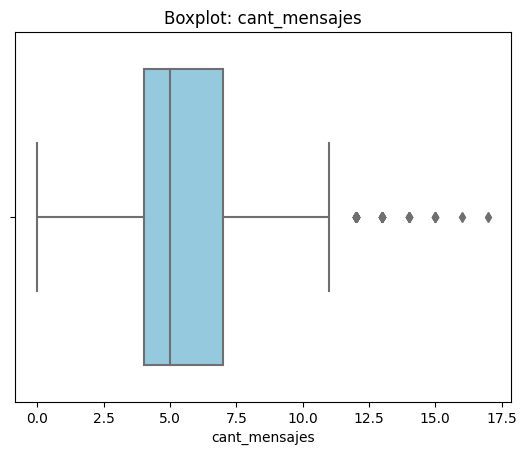

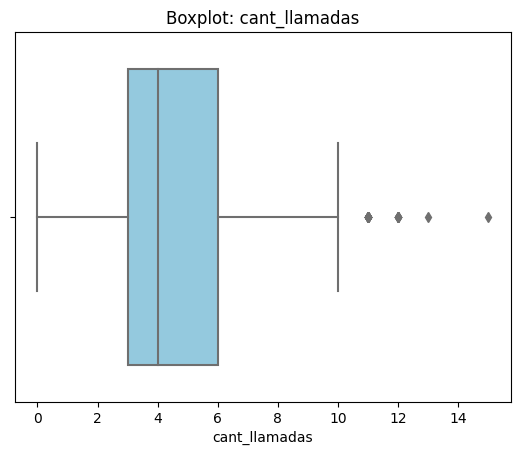

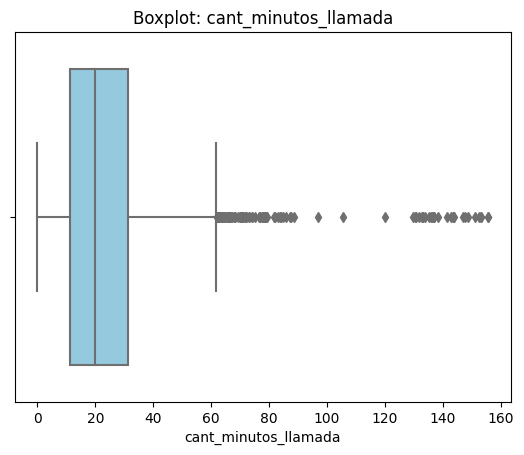

In [34]:
# Visualizando usando BoxPlot 

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 
- **Age**`: presenta distribucion simetrica. La grafica presenta una concentración de clientes entre los 32 y 62 años.

- **cant_mensajes**: Tiene una concentración de valores entre 4 y 7 mensajes, se evidencia posibles valores atípicos en los valores más altos llegando a ser mas de 14 mensajes.

- **cant_llamadas**: Presenta sesgo a la derecha, teniendo su concentracion entre los 3 a 6, se comprueba posibles outliers.

- **cant_minutos_llamada**: Presenta una distribución sesgada hacia la derecha y varios posibles valores atípicos. La mayor concentración se encuentra entre 15 y 20 minutos, aunque algunos registros alcanzan hasta 155 minutos. Se recomienda revisar estos valores para determinar si corresponden a consumos reales o a posibles errores o sentinels.

In [35]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    print(f"{col}': Q1 : {Q1}, Q3 : {Q3} IQR: {IQR}")



cant_mensajes': Q1 : 4.0, Q3 : 7.0 IQR: 3.0
cant_llamadas': Q1 : 3.0, Q3 : 6.0 IQR: 3.0
cant_minutos_llamada': Q1 : 11.12, Q3 : 31.415 IQR: 20.295


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
 Se recomienda mantener los outliers, ya que pueden representar usuarios con un consumo elevado de mensajes. Eliminarlos podría ocasionar la pérdida de información relevante para comprender los hábitos de uso de los clientes.
- cant_llamadas: mantener o no outliers, porqué?
Se recomienda mantener los outliers, porque pueden corresponder a usuarios que realizan una mayor cantidad de llamadas. Estos registros pueden aportar información importante sobre los patrones de consumo.
- cant_minutos_llamada: mantener o no outliers, porqué?
 Se identifican posibles outliers debido a la diferencia entre el tercer cuartil (31.415 minutos) y el valor máximo (155.69 minutos). Se recomienda revisar estos registros para determinar si corresponden a consumos reales o a errores de registro.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso

def clasificar_uso(row):
    grupo_uso_llamadas=row['cant_llamadas']
    grupo_uso_mensajes=row['cant_mensajes']

    if grupo_uso_llamadas < 5 and grupo_uso_mensajes < 5:
            return 'Bajo uso'

    elif  grupo_uso_llamadas < 10 and grupo_uso_mensajes < 10:
                return 'Uso medio'

    else:
        return "Alto uso"

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)
print(user_profile['grupo_uso'].value_counts())




Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64


In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,258.0,7.0,3.0,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,226.0,5.0,10.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,225.0,5.0,2.0,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,530.0,11.0,3.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,229.0,4.0,3.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.



**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos



In [39]:


# rear columna grupo_edad
def clasificar_edad(row):
    grupo_edad=row['age']

    if grupo_edad < 30:
            return "Joven"

    elif  grupo_edad < 60:
                return "Adulto"

    else:
        return "Adulto Mayor"

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)
print(user_profile['grupo_edad'].value_counts())


    

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,23.70,258.0,7.0,3.0,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,33.18,226.0,5.0,10.0,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,10.74,225.0,5.0,2.0,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,8.99,530.0,11.0,3.0,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,8.01,229.0,4.0,3.0,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

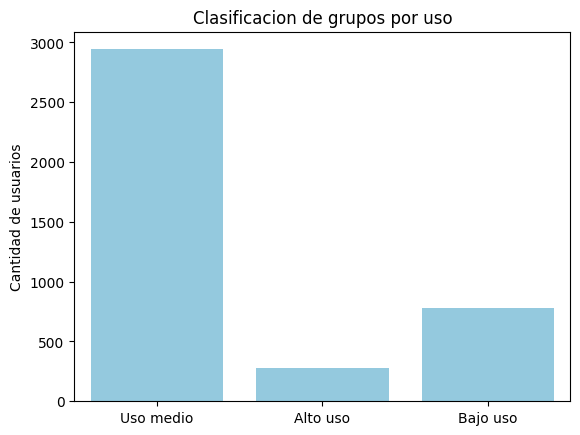

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso", color="skyblue")
plt.title("Clasificacion de grupos por uso")
plt.xlabel("") 
plt.ylabel("Cantidad de usuarios")  
plt.show()


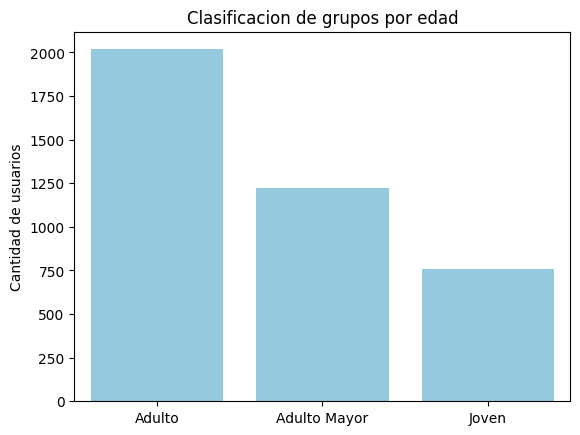

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad", color="skyblue")
plt.title("Clasificacion de grupos por edad")
plt.xlabel("") 
plt.ylabel("Cantidad de usuarios")  
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

Durante la limpieza se identificaron valores anormales en las columnas age y city, como -999 y ?, además de comproba valores vacíos y registros duplicados. También fue necesario convertir las columnas reg_date y date al formato de fecha para facilitar el análisis temporal.

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

 La segmentación por edad muestra que el grupo de adultos, entre 30 y 60 años, representa el 50,45 % de los usuarios. Por otra parte, la segmentación por nivel de uso indica que el 73,57 % de los usuarios pertenece al grupo de consumo medio.

Estos resultados muestran que ConnectaTel tiene una concentración importante de clientes adultos y de consumo medio, lo que permite orientar las estrategias comerciales hacia sus necesidades y hábitos de uso.     
  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

 Los segmentos de adultos y usuarios de consumo medio son prioritarios por su representatividad dentro de la base de clientes. Atender adecuadamente sus necesidades podría contribuir a mejorar la satisfacción, la fidelización y las oportunidades de venta.

Sin embargo, para determinar cuáles son realmente los segmentos más rentables, es necesario analizar también los ingresos, los costos y la rentabilidad asociados a cada grupo.
  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

Se identificaron posibles valores atípicos en cant_minutos_llamada, con registros que superan considerablemente el rango habitual de consumo. Estos valores podrían representar clientes con un uso elevado o posibles errores en los datos.

Antes de tomar decisiones sobre tarifas o límites de consumo, se recomienda validar estos registros. Si corresponden a consumos reales, podrían ayudar a identificar oportunidades para ofrecer planes especializados; si son errores, podrían distorsionar las estimaciones de consumo y rentabilidad.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

Se recomienda evaluar la creación de un plan intermedio entre los planes Básico y Premium, considerando que el 73,57 % de los usuarios se encuentra en el segmento de consumo medio.

Antes de implementarlo, es conveniente analizar el consumo promedio y mediano de mensajes, llamadas y minutos, así como los ingresos y costos de cada segmento. Esto permitiría establecer límites y precios competitivos que respondan a las necesidades de los clientes y mantengan la rentabilidad del negocio.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

-Se identificaron valores anormales (-999 y ?), datos vacíos y registros duplicados que podían afectar la calidad del análisis.

-Se corrigieron los tipos de datos de las columnas reg_date y date para facilitar el análisis temporal.

🔍 **Segmentos por Edad**

-El grupo de adultos, entre 30 y 60 años, representa el 50,45 % de los usuarios, siendo el segmento más numeroso.

-Este grupo constituye una prioridad para diseñar estrategias de fidelización y ofertas adaptadas a sus necesidades.


📊 **Segmentos por Nivel de Uso**

-El 73,57 % de los usuarios pertenece al segmento de consumo medio, lo que evidencia una concentración importante de clientes con este patrón de uso.

-Se identificaron posibles valores extremos en los minutos de llamadas, que deben validarse para determinar si corresponden a consumos reales o errores de registro


➡️ Esto sugiere que ConnectaTel puede orientar sus estrategias comerciales hacia los adultos y los usuarios de consumo medio, sin descuidar a los clientes de consumo elevado, quienes podrían tener necesidades diferentes.


💡 **Recomendaciones**

Evaluar la creación de un plan intermedio entre Básico y Premium, ajustado a los patrones reales de consumo de los usuarios, implementar pruebas comerciales del nuevo plan y medir su aceptación.

Validar los valores extremos y analizar los ingresos y costos por segmento para identificar oportunidades de rentabilidad.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`